# Employee Performance & Attrition Prediction — Sabor International Academy

This project analyzes workforce data for **Sabor International Academy** to identify factors associated with employee attrition and support proactive retention planning. It includes exploratory analysis, a composite performance index based on **job satisfaction, work-life balance, and performance rating**, and **3 classification models**: Logistic Regression, Decision Tree, and Random Forest.


# Import necessary libraries

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

import warnings
warnings.filterwarnings('ignore')

### Code Explanation:

#### **Step 1: Import Necessary Libraries**
- `import pandas as pd`: Imports the Pandas library, which is used for data manipulation and analysis.
- `import numpy as np`: Imports the NumPy library for numerical operations, such as handling arrays and mathematical functions.
- `import matplotlib.pyplot as plt`: Imports the Matplotlib library, which is used for creating visualizations such as plots and charts.
- `import seaborn as sns`: Imports the Seaborn library, which is built on top of Matplotlib and provides a higher-level interface for drawing statistical graphics.
- `from sklearn.model_selection import train_test_split`: Imports the function used for splitting the dataset into training and testing sets.
- `from sklearn.preprocessing import StandardScaler`: Imports the StandardScaler class, which is used to scale/normalize features to have a mean of 0 and a standard deviation of 1.
- `from sklearn.impute import SimpleImputer`: Imports the SimpleImputer class, which is used for handling missing data by filling in missing values using a strategy like mean, median, or most frequent.
- `from sklearn.ensemble import RandomForestClassifier`: Imports the RandomForestClassifier model from scikit-learn for classification tasks.
- `from sklearn.metrics import accuracy_score, classification_report, confusion_matrix`: Imports evaluation metrics for classification tasks, such as accuracy, detailed classification report, and confusion matrix.
- `from sklearn.linear_model import LogisticRegression`: Imports the Logistic Regression model for binary classification tasks.
- `from sklearn.tree import DecisionTreeClassifier`: Imports the DecisionTreeClassifier model for classification tasks based on decision trees.
- `from sklearn.model_selection import cross_val_score`: Imports the cross_val_score function, which is used for cross-validation to evaluate the model performance by splitting the dataset into multiple parts.

#### **Step 2: Ignore Warnings**
- `import warnings`: Imports the warnings module.
- `warnings.filterwarnings('ignore')`: Ignores any warnings that might appear during the execution of the code, which helps keep the output clean and focused on the results.

# Data Preprocessing

In [4]:
# Load the dataset
df = pd.read_csv('/Users/mdshahriar/Downloads/Python Projects/Project 7/employee_performance_attrition.csv')

# Handle missing values (if any)
imputer = SimpleImputer(strategy='most_frequent')
df = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

# Dealing with data types
df['Attrition'] = pd.to_numeric(df['Attrition'], errors='coerce')

# Encode categorical variables
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})
df['Department'] = df['Department'].map({'HR': 0, 'IT': 1, 'Sales': 2, 'Marketing': 3, 'Finance': 4})
df['JobRole'] = df['JobRole'].map({'Manager': 0, 'Developer': 1, 'Analyst': 2, 'Executive': 3})
df['OverTime'] = df['OverTime'].map({'No': 0, 'Yes': 1})

# Normalize numerical features
scaler = StandardScaler()
df[['Age', 'Salary', 'YearsAtCompany']] = scaler.fit_transform(df[['Age', 'Salary', 'YearsAtCompany']])

### Code Explanation:

#### **Step 1: Load the Dataset**
- `df = pd.read_csv('/Users/mdshahriar/Downloads/Python Projects/Project 7/employee_performance_attrition.csv')`:
  - This line loads the employee performance and attrition dataset from the specified CSV file into a Pandas DataFrame (`df`).

#### **Step 2: Handle Missing Values**
- `imputer = SimpleImputer(strategy='most_frequent')`:
  - Initializes a SimpleImputer object with the strategy of replacing missing values with the most frequent value (mode) in the column.
  
- `df = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)`:
  - Applies the imputer to the entire dataset, filling any missing values with the most frequent value in the respective column. The result is converted back into a DataFrame with the original column names.

#### **Step 3: Deal with Data Types**
- `df['Attrition'] = pd.to_numeric(df['Attrition'], errors='coerce')`:
  - Converts the 'Attrition' column to numeric values. If there are any non-numeric values, they will be converted to `NaN` (using `errors='coerce'`).

#### **Step 4: Encode Categorical Variables**
- `df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})`:
  - Encodes the 'Gender' column as 0 for 'Male' and 1 for 'Female'.
  
- `df['Department'] = df['Department'].map({'HR': 0, 'IT': 1, 'Sales': 2, 'Marketing': 3, 'Finance': 4})`:
  - Encodes the 'Department' column with numerical values for each department (0 for HR, 1 for IT, etc.).
  
- `df['JobRole'] = df['JobRole'].map({'Manager': 0, 'Developer': 1, 'Analyst': 2, 'Executive': 3})`:
  - Encodes the 'JobRole' column with numerical values corresponding to different job roles.

- `df['OverTime'] = df['OverTime'].map({'No': 0, 'Yes': 1})`:
  - Encodes the 'OverTime' column with 0 for 'No' and 1 for 'Yes'.

#### **Step 5: Normalize Numerical Features**
- `scaler = StandardScaler()`:
  - Initializes the StandardScaler, which standardizes the features by removing the mean and scaling to unit variance (i.e., normalization).
  
- `df[['Age', 'Salary', 'YearsAtCompany']] = scaler.fit_transform(df[['Age', 'Salary', 'YearsAtCompany']])`:
  - Applies the StandardScaler to the numerical columns 'Age', 'Salary', and 'YearsAtCompany' to normalize them. This ensures that all features have the same scale, which is important for machine learning models that rely on distance metrics.


# Exploratory Data Analysis (EDA)

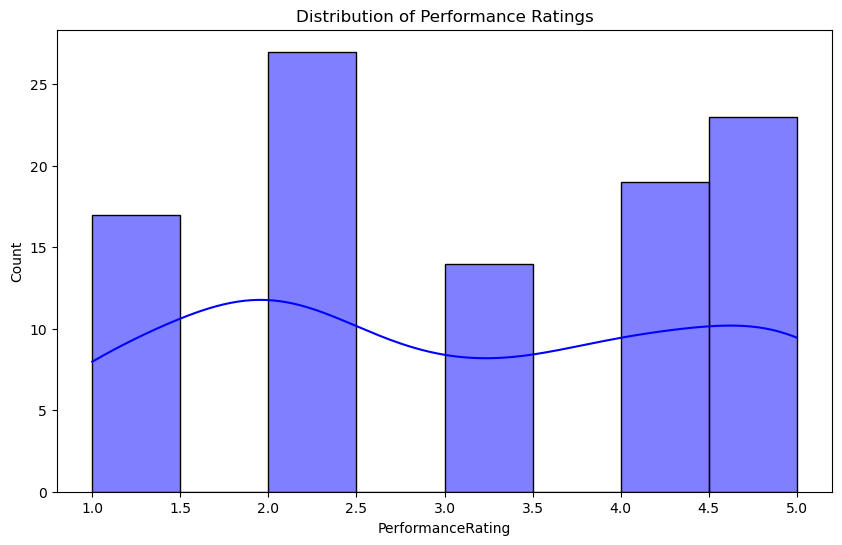

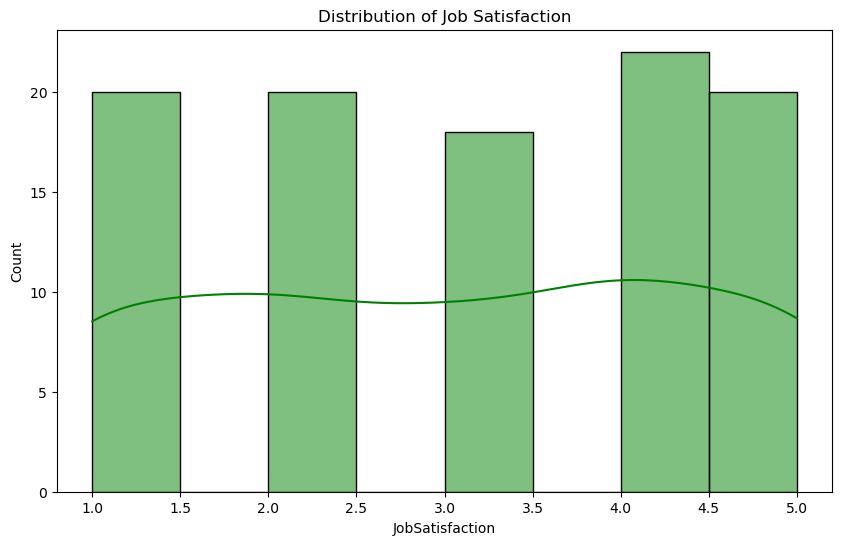

In [7]:
# Visualize distributions of key variables
plt.figure(figsize=(10, 6))
sns.histplot(df['PerformanceRating'], kde=True, color='blue')
plt.title('Distribution of Performance Ratings')
plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(df['JobSatisfaction'], kde=True, color='green')
plt.title('Distribution of Job Satisfaction')
plt.show()

### Code Explanation:

#### **Step 1: Visualize Distribution of 'PerformanceRating'**
- `plt.figure(figsize=(10, 6))`: Sets the size of the plot to 10x6 inches for better visibility.
  
- `sns.histplot(df['PerformanceRating'], kde=True, color='blue')`:
  - Plots a histogram of the 'PerformanceRating' column from the dataset.
  - The `kde=True` argument overlays a Kernel Density Estimate (KDE) curve on top of the histogram to show the probability density function.
  - The `color='blue'` argument sets the color of the histogram bars and the KDE curve to blue.
  
- `plt.title('Distribution of Performance Ratings')`: Sets the title of the plot to indicate that it is visualizing the distribution of performance ratings.
  
- `plt.show()`: Displays the histogram.

#### **Step 2: Visualize Distribution of 'JobSatisfaction'**
- `plt.figure(figsize=(10, 6))`: Sets the figure size for the next plot.
  
- `sns.histplot(df['JobSatisfaction'], kde=True, color='green')`:
  - Plots a histogram for the 'JobSatisfaction' column, similar to the previous plot, with a KDE curve overlayed.
  - The `color='green'` argument sets the color of the histogram bars and KDE curve to green.
  
- `plt.title('Distribution of Job Satisfaction')`: Sets the title of the plot to show that it represents job satisfaction distribution.
  
- `plt.show()`: Displays the histogram for job satisfaction.


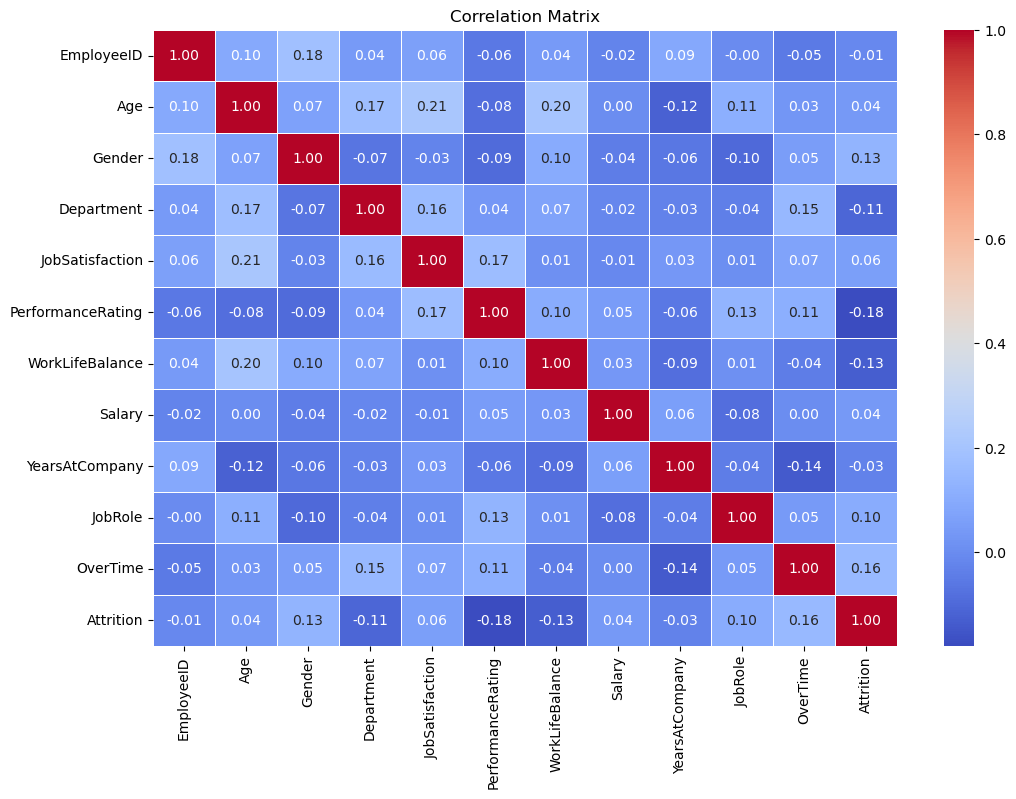

In [8]:
# Correlation matrix
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

### Code Explanation:

#### **Step 1: Generate the Correlation Matrix**
- `plt.figure(figsize=(12, 8))`: Sets the figure size to 12x8 inches for better visualization of the correlation matrix.

- `sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)`:
  - `df.corr()` computes the correlation matrix for all numerical features in the DataFrame. This matrix shows the correlation between pairs of numerical variables.
  - `annot=True`: Annotates each cell in the heatmap with the correlation value.
  - `cmap='coolwarm'`: Uses a color map where cooler colors (blue) represent negative correlations and warmer colors (red) represent positive correlations.
  - `fmt='.2f'`: Formats the correlation values to two decimal places for clarity.
  - `linewidths=0.5`: Adds lines between the cells for better separation.

- `plt.title('Correlation Matrix')`: Sets the title of the plot to indicate that it is a correlation matrix.
  
- `plt.show()`: Displays the heatmap.

# Feature Engineering

In [10]:
# Create performance index: job satisfaction, work-life balance, and performance rating
df['PerformanceIndex'] = df['JobSatisfaction'] * df['WorkLifeBalance'] * df['PerformanceRating']

### Code Explanation:

#### **Step 1: Create a Performance Index**
- `df['PerformanceIndex'] = df['JobSatisfaction'] * df['WorkLifeBalance'] * df['PerformanceRating']`:
  - This line creates a new feature called 'PerformanceIndex' by multiplying the values from the 'JobSatisfaction', 'WorkLifeBalance', and 'PerformanceRating' columns.
  - The idea behind this index is to combine three important employee factors (job satisfaction, work-life balance, and performance rating) into a single score. A higher performance index indicates better overall performance based on these factors.

# Model Development for Attrition Prediction

In [33]:
# Define features (X) and target (y)
X = df.drop(columns=['EmployeeID', 'Attrition'])
y = df['Attrition']

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize classifiers
logreg = LogisticRegression()
decision_tree = DecisionTreeClassifier(random_state=42)
random_forest = RandomForestClassifier(random_state=42)

# Fit models
logreg.fit(X_train, y_train)
decision_tree.fit(X_train, y_train)
random_forest.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

### Code Explanation:

#### **Step 1: Define Features (X) and Target (y)**
- `X = df.drop(columns=['EmployeeID', 'Attrition'])`: 
  - This line defines the feature matrix `X` by dropping the 'EmployeeID' (which is not useful for prediction) and 'Attrition' columns (which is the target variable).
  - The remaining columns are used as features for the 3 classification models.
  
- `y = df['Attrition']`: 
  - Defines the target variable `y` as the 'Attrition' column, which indicates whether the employee left Sabor International Academy (1) or stayed (0).

#### **Step 2: Split Data into Training and Test Sets**
- `X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)`:
  - Splits the data into training and testing sets, with 70% of the data used for training and 30% for testing.
  - `random_state=42` ensures that the split is reproducible.

#### **Step 3: Initialize Classifiers**
- `logreg = LogisticRegression()`: 
  - Initializes the Logistic Regression model, which will be used to predict the likelihood of employee attrition.
  
- `decision_tree = DecisionTreeClassifier(random_state=42)`: 
  - Initializes the Decision Tree classifier, which will create a model based on decision rules.
  
- `random_forest = RandomForestClassifier(random_state=42)`:
  - Initializes the Random Forest classifier, which is an ensemble method using multiple decision trees to make predictions.

#### **Step 4: Fit Models**
- `logreg.fit(X_train, y_train)`:
  - Trains the Logistic Regression model on the training data (`X_train` and `y_train`).
  
- `decision_tree.fit(X_train, y_train)`:
  - Trains the Decision Tree model on the training data (`X_train` and `y_train`).
  
- `random_forest.fit(X_train, y_train)`:
  - Trains the Random Forest model on the training data (`X_train` and `y_train`).

# Model Evaluation

Logistic Regression Accuracy: 0.4666666666666667
Decision Tree Accuracy: 0.5333333333333333
Random Forest Accuracy: 0.6333333333333333

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.53      0.47      0.50        17
           1       0.40      0.46      0.43        13

    accuracy                           0.47        30
   macro avg       0.47      0.47      0.46        30
weighted avg       0.48      0.47      0.47        30


Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.47      0.53        17
           1       0.47      0.62      0.53        13

    accuracy                           0.53        30
   macro avg       0.54      0.54      0.53        30
weighted avg       0.55      0.53      0.53        30


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.59   

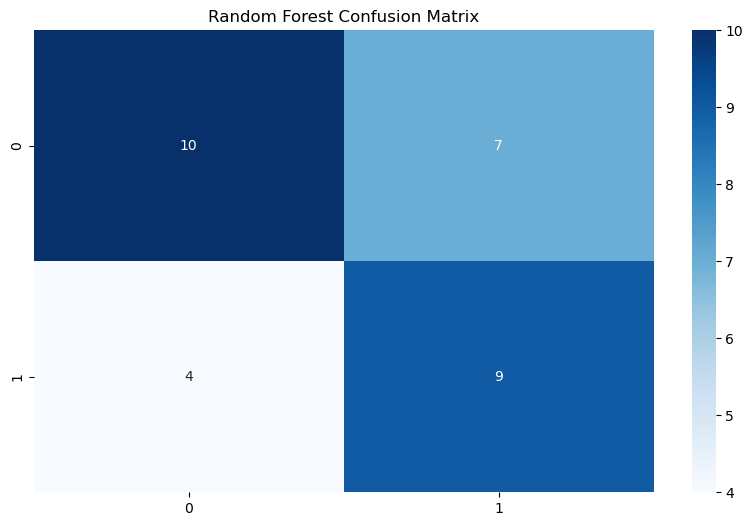

Random Forest Cross-Validation Scores: [0.5  0.55 0.8  0.5  0.6 ]
Average Cross-Validation Score: 0.5900000000000001


In [38]:
# Evaluate models on test data
y_pred_logreg = logreg.predict(X_test)
y_pred_tree = decision_tree.predict(X_test)
y_pred_rf = random_forest.predict(X_test)

# Accuracy scores
print('Logistic Regression Accuracy:', accuracy_score(y_test, y_pred_logreg))
print('Decision Tree Accuracy:', accuracy_score(y_test, y_pred_tree))
print('Random Forest Accuracy:', accuracy_score(y_test, y_pred_rf))

# Classification reports
print("\nLogistic Regression Classification Report:")
print(classification_report(y_test, y_pred_logreg))

print("\nDecision Tree Classification Report:")
print(classification_report(y_test, y_pred_tree))

print("\nRandom Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))

# Confusion matrices
plt.figure(figsize=(10, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, cmap='Blues', fmt='d')
plt.title('Random Forest Confusion Matrix')
plt.show()

# Cross-validation scores
cv_scores_rf = cross_val_score(random_forest, X, y, cv=5)
print("Random Forest Cross-Validation Scores:", cv_scores_rf)
print("Average Cross-Validation Score:", np.mean(cv_scores_rf))

### Code Explanation:

#### **Step 1: Evaluate Models on Test Data**
- `y_pred_logreg = logreg.predict(X_test)`:
  - Uses the Logistic Regression model to make predictions on the test data (`X_test`).

- `y_pred_tree = decision_tree.predict(X_test)`:
  - Uses the Decision Tree model to make predictions on the test data (`X_test`).

- `y_pred_rf = random_forest.predict(X_test)`:
  - Uses the Random Forest model to make predictions on the test data (`X_test`).

#### **Step 2: Accuracy Scores**
- `print('Logistic Regression Accuracy:', accuracy_score(y_test, y_pred_logreg))`:
  - Prints the accuracy score of the Logistic Regression model, which measures the proportion of correct predictions.

- `print('Decision Tree Accuracy:', accuracy_score(y_test, y_pred_tree))`:
  - Prints the accuracy score of the Decision Tree model.

- `print('Random Forest Accuracy:', accuracy_score(y_test, y_pred_rf))`:
  - Prints the accuracy score of the Random Forest model.

#### **Step 3: Classification Reports**
- `print("\nLogistic Regression Classification Report:")`:
  - Prints the classification report for Logistic Regression, showing key performance metrics like precision, recall, F1-score, and support for each class (attrition or no attrition).

- `print("\nDecision Tree Classification Report:")`:
  - Prints the classification report for the Decision Tree model.

- `print("\nRandom Forest Classification Report:")`:
  - Prints the classification report for the Random Forest model.

#### **Step 4: Confusion Matrix**
- `plt.figure(figsize=(10, 6))`:
  - Sets the figure size for the confusion matrix plot.
  
- `sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, cmap='Blues', fmt='d')`:
  - Creates a heatmap of the confusion matrix for the Random Forest model.
  - The `annot=True` argument adds the count values inside the cells.
  - The `fmt='d'` argument formats the values as integers.

- `plt.title('Random Forest Confusion Matrix')`:
  - Sets the title of the confusion matrix plot.

- `plt.show()`:
  - Displays the confusion matrix heatmap.

#### **Step 5: Cross-Validation Scores**
- `cv_scores_rf = cross_val_score(random_forest, X, y, cv=5)`:
  - Performs 5-fold cross-validation on the Random Forest model and stores the cross-validation scores.
  
- `print("Random Forest Cross-Validation Scores:", cv_scores_rf)`:
  - Prints the cross-validation scores for the Random Forest model.

- `print("Average Cross-Validation Score:", np.mean(cv_scores_rf))`:
  - Prints the average cross-validation score, which provides an overall performance estimate based on different splits of the data.

# Analysis of Job Satisfaction vs. Performance

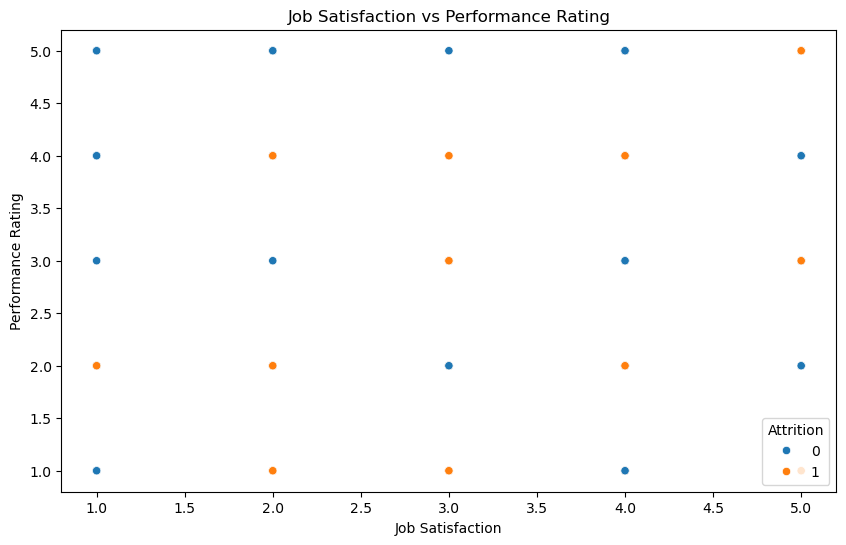

Correlation between Job Satisfaction and Performance Rating: 0.16636358710114854


In [41]:
# Plot Job Satisfaction vs Performance Ratings
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['JobSatisfaction'], y=df['PerformanceRating'], hue=df['Attrition'])
plt.title('Job Satisfaction vs Performance Rating')
plt.xlabel('Job Satisfaction')
plt.ylabel('Performance Rating')
plt.show()

# Calculate correlation
satisfaction_performance_corr = df[['JobSatisfaction', 'PerformanceRating']].corr()
print("Correlation between Job Satisfaction and Performance Rating:", satisfaction_performance_corr.iloc[0, 1])


### Code Explanation:

#### **Step 1: Plot Job Satisfaction vs Performance Ratings**
- `plt.figure(figsize=(10, 6))`: Sets the figure size to 10x6 inches for better visibility of the plot.
  
- `sns.scatterplot(x=df['JobSatisfaction'], y=df['PerformanceRating'], hue=df['Attrition'])`:
  - Creates a scatter plot with 'JobSatisfaction' on the x-axis and 'PerformanceRating' on the y-axis.
  - The `hue=df['Attrition']` argument colors the points based on whether the employee left Sabor International Academy ('Attrition'). This helps visualize how job satisfaction and performance ratings are distributed across employees who stayed and those who left.

- `plt.title('Job Satisfaction vs Performance Rating')`: Sets the title of the plot.
  
- `plt.xlabel('Job Satisfaction')`: Labels the x-axis as 'Job Satisfaction'.
  
- `plt.ylabel('Performance Rating')`: Labels the y-axis as 'Performance Rating'.
  
- `plt.show()`: Displays the scatter plot.

#### **Step 2: Calculate Correlation**
- `satisfaction_performance_corr = df[['JobSatisfaction', 'PerformanceRating']].corr()`:
  - Calculates the correlation between the 'JobSatisfaction' and 'PerformanceRating' columns. This will tell you how strongly these two variables are related to each other.
  
- `print("Correlation between Job Satisfaction and Performance Rating:", satisfaction_performance_corr.iloc[0, 1])`:
  - Prints the correlation value between 'JobSatisfaction' and 'PerformanceRating'. The correlation value ranges from -1 to 1, where:
    - A value close to 1 indicates a strong positive correlation.
    - A value close to -1 indicates a strong negative correlation.
    - A value close to 0 indicates little or no linear relationship.

# Overtime Analysis

In [44]:
# Compare performance ratings for employees who work overtime and those who don't
overtime_performance = df.groupby('OverTime')['PerformanceRating'].mean()
print("\nAverage Performance Ratings for Overtime Employees vs Non-Overtime Employees:")
print(overtime_performance)

# Compare attrition rates for overtime vs non-overtime employees
overtime_attrition = df.groupby('OverTime')['Attrition'].mean()
print("\nAttrition Rates for Overtime Employees vs Non-Overtime Employees:")
print(overtime_attrition)


Average Performance Ratings for Overtime Employees vs Non-Overtime Employees:
OverTime
0    2.886792
1    3.212766
Name: PerformanceRating, dtype: object

Attrition Rates for Overtime Employees vs Non-Overtime Employees:
OverTime
0    0.377358
1    0.531915
Name: Attrition, dtype: float64


### Code Explanation:

#### **Step 1: Compare Performance Ratings for Employees Who Work Overtime and Those Who Don’t**
- `overtime_performance = df.groupby('OverTime')['PerformanceRating'].mean()`:
  - Groups the data by the 'OverTime' column (which indicates whether an employee works overtime) and calculates the average 'PerformanceRating' for employees who work overtime (`OverTime = 1`) and those who don't (`OverTime = 0`).
  
- `print("\nAverage Performance Ratings for Overtime Employees vs Non-Overtime Employees:")`:
  - Prints a heading indicating that the following output shows the average performance ratings for overtime vs non-overtime employees.
  
- `print(overtime_performance)`:
  - Prints the average performance ratings for both overtime and non-overtime employees. This allows you to compare how working overtime correlates with employee performance ratings.

#### **Step 2: Compare Attrition Rates for Overtime vs Non-Overtime Employees**
- `overtime_attrition = df.groupby('OverTime')['Attrition'].mean()`:
  - Groups the data by the 'OverTime' column and calculates the average 'Attrition' rate for overtime vs non-overtime employees.
  - Since 'Attrition' is binary (0 for staying, 1 for leaving), this calculation gives the proportion of employees who left Sabor International Academy in each group.
  
- `print("\nAttrition Rates for Overtime Employees vs Non-Overtime Employees:")`:
  - Prints a heading indicating that the following output shows the attrition rates for overtime vs non-overtime employees.
  
- `print(overtime_attrition)`:
  - Prints the attrition rates for employees who work overtime and those who don’t. This allows you to assess whether working overtime has any relationship with employee turnover.

# Departmental Attrition and Performance Analysis

In [47]:
# Department-wise attrition and performance analysis
department_attrition = df.groupby('Department')['Attrition'].mean()
department_performance = df.groupby('Department')['PerformanceRating'].mean()

print("\nDepartment-wise Attrition Rates:")
print(department_attrition)

print("\nDepartment-wise Average Performance Ratings:")
print(department_performance)


Department-wise Attrition Rates:
Department
0    0.444444
1    0.687500
2    0.347826
3    0.500000
4    0.200000
Name: Attrition, dtype: float64

Department-wise Average Performance Ratings:
Department
0    2.925926
1      2.6875
2    3.521739
3    3.041667
4         2.8
Name: PerformanceRating, dtype: object


### Code Explanation:

#### **Step 1: Department-Wise Attrition Analysis**
- `department_attrition = df.groupby('Department')['Attrition'].mean()`:
  - This line groups the data by the 'Department' column and calculates the average 'Attrition' rate for each department. Since 'Attrition' is a binary variable (0 for staying, 1 for leaving), the mean will give the proportion of employees who left Sabor International Academy in each department.
  
- `print("\nDepartment-wise Attrition Rates:")`:
  - Prints a heading to indicate that the following output will display the attrition rates for each department.
  
- `print(department_attrition)`:
  - Prints the department-wise attrition rates, showing the proportion of employees who left Sabor International Academy in each department.

#### **Step 2: Department-Wise Performance Analysis**
- `department_performance = df.groupby('Department')['PerformanceRating'].mean()`:
  - This line groups the data by the 'Department' column and calculates the average 'PerformanceRating' for each department, helping to understand how employees in different departments perform on average.
  
- `print("\nDepartment-wise Average Performance Ratings:")`:
  - Prints a heading to indicate that the following output will display the average performance ratings for each department.
  
- `print(department_performance)`:
  - Prints the department-wise average performance ratings.

# Thank you!